# BUSI2066 · Week 11 — What Drives the Outcome: Regression


### Before you start

Drag in **this notebook** and **`satisfaction.csv`**, and select the kernel.

### Today

Every test so far answered *"is it related?"* Regression answers **"by how much, and what else
matters?"** It is the last method in the course, and it contains all the others.

> **What makes a visitor say they will come back?**

### The rule

> **AI explains. It does not write** — except where marked ⭐. Regression output is long; asking
> AI to explain a line of `summary()` is exactly the right use of it.

**Simulated records for 500 amusement park visitors.**

| Column | What it is | Scale |
|---|---|---|
| `weekend` | Did they come on a weekend? | nominal — yes / no |
| `child` | How many children they brought | count |
| `distance` | How far they travelled (the source gives no unit) | ratio |
| `rides` · `games` · `wait` · `clean` | Satisfaction with each, 1–5 | Likert, treated as interval |
| `revisit` | **Simulated intention to come back score** | **the outcome** |

⚠️ **Simulated teaching data.** The supplied file uses numerical example scores. Use it to practise the method.

**The structure is similar to a survey project:** several numerical items and one outcome. Ask which items are associated with the outcome after adjustment.

**Check the supplied scale.** Revisit ranges from 0.3 to 5.0. Six supplied scores are below 1. This is a numerical teaching outcome, not a clean 1 to 5 survey response. Keep the supplied values when reproducing this lesson. In a real survey, check the codebook and investigate values outside the stated scale before fitting a model.

---
# Part 0 · Set up, and the data

In [30]:
%pip install -q pandas numpy matplotlib seaborn scipy statsmodels


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

df = pd.read_csv('satisfaction.csv')
print(df.shape)
print("Observed score ranges:")
print(df[['rides', 'games', 'wait', 'clean', 'revisit']].agg(['min', 'max']))
print("Revisit scores below 1:", (df['revisit'] < 1).sum())
print("First five supplied rows:")
df.head()

(500, 8)
Observed score ranges:
     rides  games  wait  clean  revisit
min    3.6   2.85   2.0    3.7      0.3
max    5.0   5.00   5.0    5.0      5.0
Revisit scores below 1: 6
First five supplied rows:


,weekend,child,distance,rides,games,wait,clean,revisit
0,yes,0,114.648259,4.35,3.65,3.0,4.45,2.35
1,yes,2,27.014097,4.35,3.90,3.8,4.35,3.25
2,no,1,63.300975,4.25,4.00,3.5,4.40,3.05
3,yes,0,25.909931,4.40,3.60,3.3,4.45,1.85
4,no,4,54.718307,4.20,4.35,3.7,4.35,3.40


---
# Part 1 · Look before you model

Regression assumes straight-line relationships and dislikes predictors that duplicate each other.
Both are checked by looking — and you have the tools.

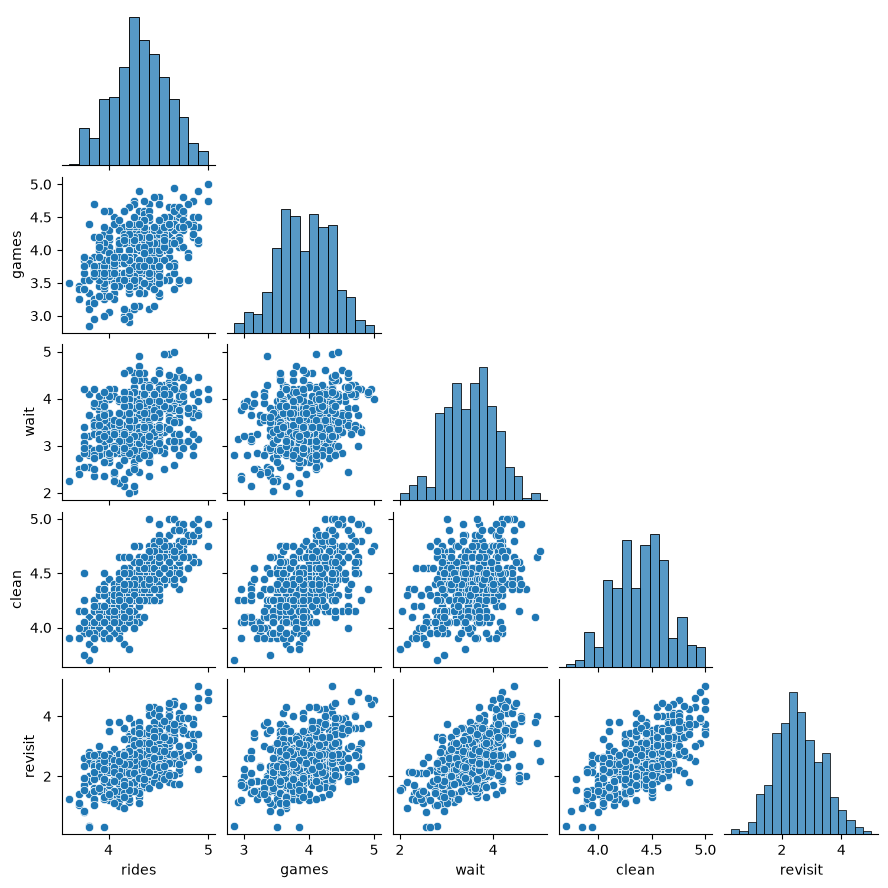

In [2]:
sns.pairplot(df[['rides', 'games', 'wait', 'clean', 'revisit']], corner=True, height=1.8)
plt.show()

`corner=True` draws only the lower triangle — half the charts, same information. Read the bottom
row: `revisit` against each satisfaction score. All four slope upward, roughly straight. Good.

In [3]:
print(df['distance'].describe().round(1))
df['log_dist'] = np.log(df['distance'])

count    500.0
mean      31.0
std       33.1
min        0.5
25%       10.3
50%       19.0
75%       39.6
max      239.2
Name: distance, dtype: float64


`distance` has a median of about 19 and a maximum of about 239 — right-skewed, week 8's problem. Logged, as
usual. No zeros, so no `+ 1`.

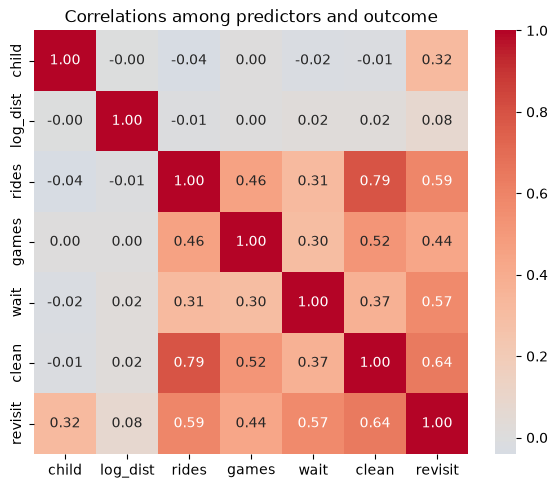

In [4]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[['child', 'log_dist', 'rides', 'games', 'wait', 'clean', 'revisit']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlations among predictors and outcome')
plt.show()

Two things to see:

- **The bottom row.** `clean` (0.64), `rides` (0.59) and `wait` (0.57) correlate most with revisit. `log_dist` has a weak unadjusted correlation (0.08).
- **Rides and cleanliness overlap strongly.** Their correlation is 0.79, but they are not identical. This overlap is called **collinearity**.

**Why include both?** We want to estimate the association between rides satisfaction and revisit at the same cleanliness score, and the association between cleanliness satisfaction and revisit at the same rides score. Correlation alone is not a reason to remove a predictor.

The concern is uncertainty: strong overlap can make individual coefficients less precise and more sensitive to changes in the data. Check their confidence intervals and interpret the estimates with care. The later m2 output shows that both retain statistically significant adjusted associations after the other satisfaction scores are included. That does not establish a causal effect.

---
# Part 2 · One predictor — simple linear regression

**Regression in words.** Linear regression estimates the straight-line association between one
**dependent variable** (DV, Y — the outcome, target or response) and one or more **independent
variables** (IVs, X — the predictors).

- The **DV should be continuous** — a number. Here: `revisit`.
- The **IVs can be either** continuous or categories — `rides` is a number, `weekend` is yes/no.
- It does two jobs: **predict** Y for a new visitor, and **explain** how much Y changes when one X goes up by 1.
- **Association does not imply causation.** This is a survey (week 4).

## 2.1 The line

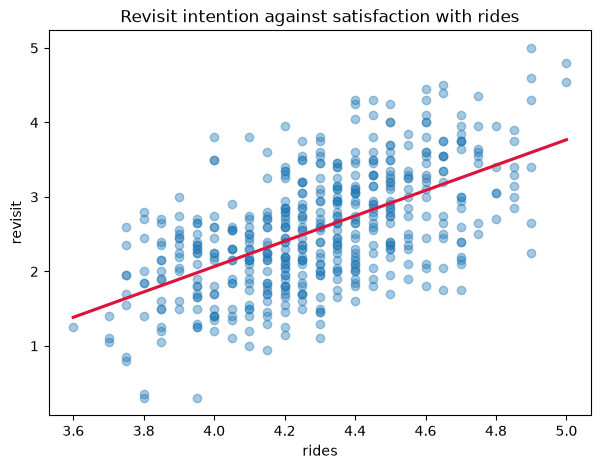

In [5]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x='rides', y='revisit', ci=None,
            scatter_kws={'alpha': 0.4}, line_kws={'color': 'crimson'})
plt.title('Revisit intention against satisfaction with rides')
plt.show()

`regplot` is a scatter plot with the best-fitting straight line drawn through it. *Best-fitting*
means: of every possible line, the one that makes the total squared vertical gap between dots and
line as small as possible — **least squares**.

For each visitor the line gives a **predicted** value ŷ. The vertical gap y − ŷ is the **residual**.
Square every residual and add them up:

$$RSS = \sum_i (y_i - \hat{y}_i)^2$$

the **residual sum of squares**. The best line is the one with the smallest RSS. `ols` stands for
*ordinary least squares*.

That line has an equation, and the equation is the model.

## 2.2 Fitting it

In [6]:
m1 = ols('revisit ~ rides', data=df).fit()

print(m1.params)

Intercept   -4.748112
rides        1.703285
dtype: float64


### One visitor, one prediction, one residual

Take the first supplied visitor. Predict from that visitor's rides score, subtract the prediction from the actual revisit score, then square the residual. This is one visitor's contribution to RSS.

`df.loc[[0]]` selects the supplied row labelled 0 as a small table. `[0]` then reads that row’s value from a result column.

In [7]:
one_visitor = df.loc[[0]]
one_prediction = m1.predict(one_visitor)[0]
one_actual = one_visitor['revisit'][0]
one_residual = one_actual - one_prediction
print("Rides score:", one_visitor['rides'][0])
print("Actual revisit:", round(one_actual, 4))
print("Predicted revisit:", round(one_prediction, 4))
print("Residual: actual minus predicted:", round(one_residual, 4))
print("Squared residual:", round(one_residual ** 2, 4))

Rides score: 4.35
Actual revisit: 2.35
Predicted revisit: 2.6612
Residual: actual minus predicted: -0.3112
Squared residual: 0.0968


`ols('revisit ~ rides')` — *revisit explained by rides* — is the same formula you used for ANOVA last
week. This time the explanatory column is a number, and the result is a **line**:

> **revisit = −4.75 + 1.70 × rides**

| | Value | Means |
|---|---|---|
| **Intercept** | −4.75 | predicted revisit when rides = 0. Meaningless here — nobody scores 0 on a 1–5 scale — but the line needs it |
| **Slope** (`rides`) | **1.70** | **each extra point of rides satisfaction goes with 1.70 more points of revisit intention** |

That slope is the thing correlation could not give you (week 8, Part 4). r told you *tight or loose*;
the slope tells you *how much*.

## 2.3 Is the slope real, and how good is the line?

In [8]:
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:                revisit   R-squared:                       0.343
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     260.4
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.97e-47
Time:                        07:00:29   Log-Likelihood:                -488.43
No. Observations:                 500   AIC:                             980.9
Df Residuals:                     498   BIC:                             989.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.7481      0.454    -10.460      0.0

📖 **`summary()` prints far more than you need.** Four numbers matter, and here is where they are:

| Look for | Value | What it says |
|---|---|---|
| `coef` on the `rides` row | **1.703** | the slope |
| `P>\|t\|` on the `rides` row | **0.000** | H₀: slope = 0. Evidence of an association in this fitted model |
| `[0.025  0.975]` on that row | **1.50 → 1.91** | 95% CI for the slope |
| `R-squared` at the top | **0.343** | the line explains **34% of the variation** in revisit |

These four you read yourself. §2.4 adds three more from the top of the table.

**R² is the one people misuse.** 0.34 means rides satisfaction accounts for about a third of why
revisit intention varies. The other two thirds is everything else — and Part 3 goes looking for it.

## 2.4 R², adjusted R², the F-statistic and the interval

**Where R² comes from.** TSS, the *total sum of squares*, is how far each visitor's revisit is from the
average ȳ, squared and added — all the variation there is. RSS is what the line leaves unexplained.

$$R^2 = \frac{TSS - RSS}{TSS} = 1 - \frac{RSS}{TSS} \qquad TSS = \sum_i (y_i - \bar{y})^2$$

R² = 1: the model explains everything (RSS = 0). R² = 0: it does no better than always predicting the
average. **Adjusted R²** = 1 − (1 − R²) × (n − 1) / (n − p − 1), with p predictors: slightly smaller,
because it **penalises extra predictors**.

The **F-statistic** tests the whole model. H₀: *every* slope is zero — the model explains nothing.

**Read one row as a connected argument.** `coef` is the estimated slope. `std err` measures its uncertainty. `t` is the coefficient divided by its standard error. `P>\|t\|` tests a population slope of zero under the model assumptions. The 95% interval gives a range of plausible slope values. A printed p of **0.000 is rounded**, not exactly zero. Small p values do not measure the size or business value of a relationship.

In [9]:
print("F-statistic:", round(m1.fvalue, 1))
print("F p-value:", m1.f_pvalue)
print("R-squared:", round(m1.rsquared, 3))
print("adjusted R-squared:", round(m1.rsquared_adj, 3))

F-statistic: 260.4
F p-value: 1.971513788110172e-47
R-squared: 0.343
adjusted R-squared: 0.342


📖 `.fvalue`, `.f_pvalue`, `.rsquared`, `.rsquared_adj` pull single numbers out of `summary()`. Read-level.

**F = 260.4, p ≈ 0**: reject H₀ — the model explains something. With one predictor this agrees with the
slope's own p. With several, it asks whether the model **as a whole** helps. R² = 0.343; adjusted R²
= 0.342, almost the same because there is only one predictor.

**The 95% interval, by hand.** The interval is the coefficient plus or minus about 2 standard errors:

In [10]:
print(m1.params['rides'])      # coef
print(m1.bse['rides'])         # std err
print(m1.conf_int())           # the 95% interval for every coefficient

1.703285483410205
0.10554615174616544
                  0         1
Intercept -5.640006 -3.856219
rides      1.495915  1.910656


📖 `.bse` gives coefficient standard errors and `.conf_int()` gives their fitted confidence intervals.

About two standard errors is a useful rough check: 1.703 ± 1.96 × 0.106 is about 1.50 to 1.91. The value 1.96 is a standard normal critical value used as a large sample approximation. The fitted OLS interval uses a t critical value with the model's residual degrees of freedom. Use `conf_int()` for the reported interval.

The interval excludes zero, agreeing with the small p value. It describes uncertainty in the population association under the model assumptions. It is not a prediction interval for one visitor.

## 2.5 Use the line

In [11]:
new_visitor = pd.DataFrame({'rides': [3.0, 4.0, 5.0]})      # three made-up visitors
print(m1.predict(new_visitor))

0    0.361744
1    2.065030
2    3.768315
dtype: float64


📖 `pd.DataFrame({'rides': [3.0, 4.0, 5.0]})` builds a small table by hand: the name in quotes is the
column, the list in square brackets is its values. `predict` needs the same column name the model was
fitted on.

A visitor who scores rides at 5 is predicted to score revisit at **3.77**. That is the model doing
the thing models are for.

**Check the range.** The observed rides scores run from 3.6 to 5.0. Our made-up visitor with rides = 3.0 is outside that range. This is **extrapolation**. Its predicted revisit score is about 0.36. A straight line does not keep predictions inside a survey scale.

The predictions for rides = 4 and 5 are about 2.07 and 3.77. They are fitted predictions, not guaranteed individual outcomes. R² describes this fitted sample. No separate test sample has been evaluated, so accuracy for new visitors has not been established.

## 2.6 Five assumptions, and the residual plots

Linear regression rests on five assumptions:

| # | Assumption | How you check it |
|---|---|---|
| 1 | **Straight-line** relationship between each X and Y | the pair plot (Part 1) |
| 2 | **No exact linear duplication** among the Xs; strong overlap can increase uncertainty | the heatmap (Part 1) |
| 3 | Residuals are **independent** of each other | use a meaningful order, such as collection time or batch; file position alone may not help |
| 4 | Residuals are roughly **normal** | QQ plot of the residuals (week 5) |
| 5 | Residuals have the **same spread** everywhere | residuals against the **predictions**: a shapeless band |

A **residual** is what the model got wrong for one visitor. These are different checks on what the model leaves unexplained. Three pictures check them.

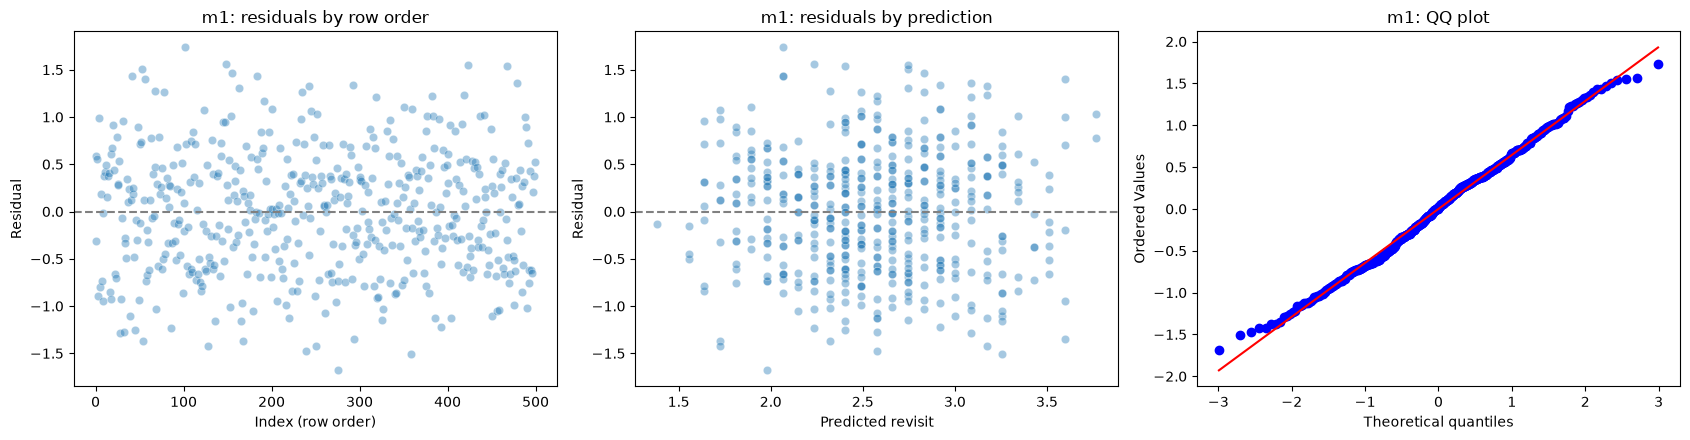

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.scatterplot(x=df.index, y=m1.resid, alpha=0.4, ax=axes[0])
axes[0].axhline(0, color='grey', linestyle='--')
axes[0].set_xlabel('Index (row order)'); axes[0].set_ylabel('Residual')
axes[0].set_title('m1: residuals by row order')

sns.scatterplot(x=m1.fittedvalues, y=m1.resid, alpha=0.4, ax=axes[1])
axes[1].axhline(0, color='grey', linestyle='--')
axes[1].set_xlabel('Predicted revisit'); axes[1].set_ylabel('Residual')
axes[1].set_title('m1: residuals by prediction')

import scipy.stats as stats
stats.probplot(m1.resid, plot=axes[2])
axes[2].set_title('m1: QQ plot')

plt.tight_layout()
plt.show()

📖 `m1.resid` holds the residuals, one per visitor; `m1.fittedvalues` the predictions ŷ; `df.index` the
row numbers 0 to 499. All read-level.

- **Left (assumption 3):** the x axis is file row number. A pattern can be informative if rows follow collection time or another meaningful order. This file does not establish that order, so this plot cannot verify independence. A wave is only one made-up warning example: a trend, sudden jump or long runs above or below zero can matter too.
- **Middle (assumption 5):** x is the predicted revisit score and y is the residual, actual minus predicted. A similar vertical spread across x is what we look for. In the made-up funnel on the slide, residuals stay near zero at lower predictions and spread further above and below zero at higher predictions. Errors are therefore larger at higher predictions. A funnel can also narrow in the other direction. This is changing spread, not a curve: a curve means the average error changes with the prediction, suggesting a problem with the model form.
- **Right (assumption 4):** close to the line. The two ends bend in a little — slightly thinner tails
  than a normal curve — which is no worry with 500 visitors. If the points bent **away** from the line,
  the residuals would **not be normal**: skewed, or with heavy tails. Week 5's QQ plot, doing one more job.

These plots look for warning signs. No visible pattern does not prove independent errors, normal errors or a correct model. Repeat the checks for the final model after changing predictors.

---
# Part 3 · Several predictors — multiple regression

Rides explained a third. Add the other three satisfaction scores.

In [13]:
m2 = ols('revisit ~ rides + games + wait + clean', data=df).fit()
m2_output = pd.DataFrame({'coefficient': m2.params, 'p_value': m2.pvalues,
                          'CI_low': m2.conf_int()[0], 'CI_high': m2.conf_int()[1]})
print(m2_output)
print("R-squared:", round(m2.rsquared, 4))

           coefficient       p_value    CI_low   CI_high
Intercept    -6.570460  1.104784e-45 -7.389156 -5.751764
rides         0.529078  2.186256e-04  0.249940  0.808216
games         0.153336  2.690296e-02  0.017600  0.289072
wait          0.553326  1.406114e-27  0.459385  0.647268
clean         0.984213  1.539136e-09  0.670111  1.298314
R-squared: 0.5586


Four slopes now. R² rises from 0.3434 to 0.5586 in the same simulated sample.

**Holding the others constant:** a one point higher rides satisfaction score is associated with a 0.529 point higher revisit score, at the same games, wait and clean satisfaction scores. Its 95% interval is about 0.250 to 0.808 and p is about 0.000219.

The rides slope falls from 1.703 alone to 0.529 together. Its association overlaps with the other scores. This does not establish which satisfaction score causes revisit intention.

The cleanliness coefficient, 0.984, is the largest among these four satisfaction scores. That does not make it the best spending decision. Costs and the outcomes of an intervention have not been measured. A larger coefficient and a smaller p value answer different questions.

## 3.1 Is the bigger model actually better?

Adding predictors cannot lower fitted R² when the same rows and an intercept are used. A **nested comparison** tests whether the extra coefficients are all zero. Every predictor in the smaller model must also appear in the larger model, and both must use the same rows.

In [14]:
anova_lm(m1, m2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,498.0,206.529533,0.0,NaN,NaN,NaN
1,495.0,138.828821,3.0,67.700712,80.463245,2.065908e-42


Read `Pr(>F)` on the second row. The p value is about 2.07 × 10⁻⁴², so the comparison supports including the extra terms in m2.

For this lesson, retain the simpler nested model unless the test gives clear evidence for the extra terms. A p value above 0.05 is not proof that the extra coefficients are zero. This classroom selection rule compares fit in the sample. It does not establish accuracy for new visitors.

---
# Part 4 · Categories as predictors

`weekend` is yes/no. `child` is a count. Both can go in a regression — `ols` turns a yes/no column into
0/1 automatically. First, all seven predictors, with `child` as a count.

In [15]:
m3 = ols('revisit ~ weekend + child + log_dist + rides + games + wait + clean', data=df).fit()

print(m3.params.round(3))
print()
print(m3.pvalues.round(3))
print()
print("R-squared:", round(m3.rsquared, 3))

Intercept        -7.103
weekend[T.yes]   -0.036
child             0.180
log_dist          0.052
rides             0.619
games             0.138
wait              0.562
clean             0.922
dtype: float64

Intercept         0.000
weekend[T.yes]    0.373
child             0.000
log_dist          0.012
rides             0.000
games             0.020
wait              0.000
clean             0.000
dtype: float64

R-squared: 0.679


Read `weekend[T.yes]`: `ols` built a 0/1 column (1 = weekend) and named the row `[T.yes]`. Its p is
**0.37** — there is no clear evidence of a weekend difference after adjustment. `child` has slope **0.18**: each extra child goes with
0.18 more points of revisit. R² = **0.68**.

## 4.1 A count, recoded as yes/no

Is it *how many* children that matters, or *whether* there are any? Make a yes/no column and refit.

In [16]:
df['has_child'] = df['child'] > 0

m4 = ols('revisit ~ weekend + has_child + log_dist + rides + games + wait + clean', data=df).fit()

print(m4.pvalues.round(3))
print()
print("R-squared:", round(m4.rsquared, 3))

Intercept            0.000
weekend[T.yes]       0.597
has_child[T.True]    0.000
log_dist             0.116
rides                0.000
games                0.083
wait                 0.000
clean                0.000
dtype: float64

R-squared: 0.774


`df['child'] > 0` is a comparison asked of every row — `True` or `False` — stored as a new column.
Same trick as week 10's filtering, kept as data.

**Same information, recoded — and R² jumps from 0.68 to 0.77.** In this data, *whether* a visitor brings
children goes with revisit far more than *how many*. A count is not always best used as a number.

But look at the p-values: `weekend` (0.60), `log_dist` (0.12) and `games` (0.08) are all above 0.05.
There is no clear evidence for each adjusted association at the 5% level. Test the three terms together before selecting the simpler model.

## 4.2 Drop what does not help

**Reference groups.** `weekend[T.yes]` compares yes with no. `has_child[T.True]` compares visitors with children with visitors without children. In the later m5 model the latter difference is about 0.806 revisit points, holding rides, wait and clean scores constant.

**This replacement is not a nested comparison.** m3 uses a child count and m4 uses any children. Neither contains the other. Do not apply the nested model ANOVA rule to the m3 versus m4 replacement.

In [17]:
m5 = ols('revisit ~ has_child + rides + wait + clean', data=df).fit()

print(m5.params.round(3))
print()
print("R-squared:", round(m5.rsquared, 3))
print()
anova_lm(m5, m4)

Intercept           -7.309
has_child[T.True]    0.806
rides                0.656
wait                 0.578
clean                1.018
dtype: float64

R-squared: 0.772



,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,495.0,71.869484,0.0,NaN,NaN,NaN
1,492.0,71.016762,3.0,0.852723,1.969204,0.117679


Four predictors remain. R² falls slightly from 0.7742 in m4 to 0.7715 in m5. The nested comparison gives p = 0.1177. It does not find clear evidence that the three extra terms improve the fit, so we retain m5 as the simpler classroom model.

This does not prove that the removed variables have zero association. It also does not establish future prediction performance.

In m5, `has_child[T.True]` is about +0.806. The reference group is visitors without children. At the same rides, wait and clean satisfaction scores, visitors with children have an estimated revisit score 0.806 points higher.

## 4.3 The final model in one sentence

In this simulated sample, one point higher cleanliness satisfaction is associated with about 1.02 more revisit points (95% interval 0.80 to 1.24), holding the other included predictors constant. The final model explains about 77.15% of the sample variation. Causation and accuracy for new visitors have not been established.

**Reporting checklist:** state the estimated association and its units, uncertainty, model fit, limits and the evidence needed before making a business investment.

## 4.4 The model journey

Compare what changed rather than choosing from model names alone. All five models use the same supplied rows. The m3 to m4 replacement is not nested. The m5 versus m4 test is nested.

In [18]:
model_journey = pd.DataFrame({
    'model': ['m1', 'm2', 'm3', 'm4', 'm5'],
    'change': ['rides only', 'four satisfaction scores', 'add weekend, child count, log distance',
               'replace child count with any children', 'remove weekend, log distance, games'],
    'R_squared': [m1.rsquared, m2.rsquared, m3.rsquared, m4.rsquared, m5.rsquared],
    'adjusted_R_squared': [m1.rsquared_adj, m2.rsquared_adj, m3.rsquared_adj, m4.rsquared_adj, m5.rsquared_adj]
})
model_journey

,model,change,R_squared,adjusted_R_squared
0,m1,rides only,0.343380,0.342061
1,m2,four satisfaction scores,0.558621,0.555054
2,m3,"add weekend, child count, log distance",0.678605,0.674032
3,m4,replace child count with any children,0.774216,0.771004
4,m5,"remove weekend, log distance, games",0.771505,0.769659


## 4.5 Check the final model again

These plots use **m5**, not m1. Look for order patterns only when the row order has a known meaning. Collection order is not established by this file. Check curves or changing vertical spread against predictions and departures from the QQ reference line. A funnel shows that error size changes across the predictions. Treat these as checks for warning signs, not proof that assumptions hold.

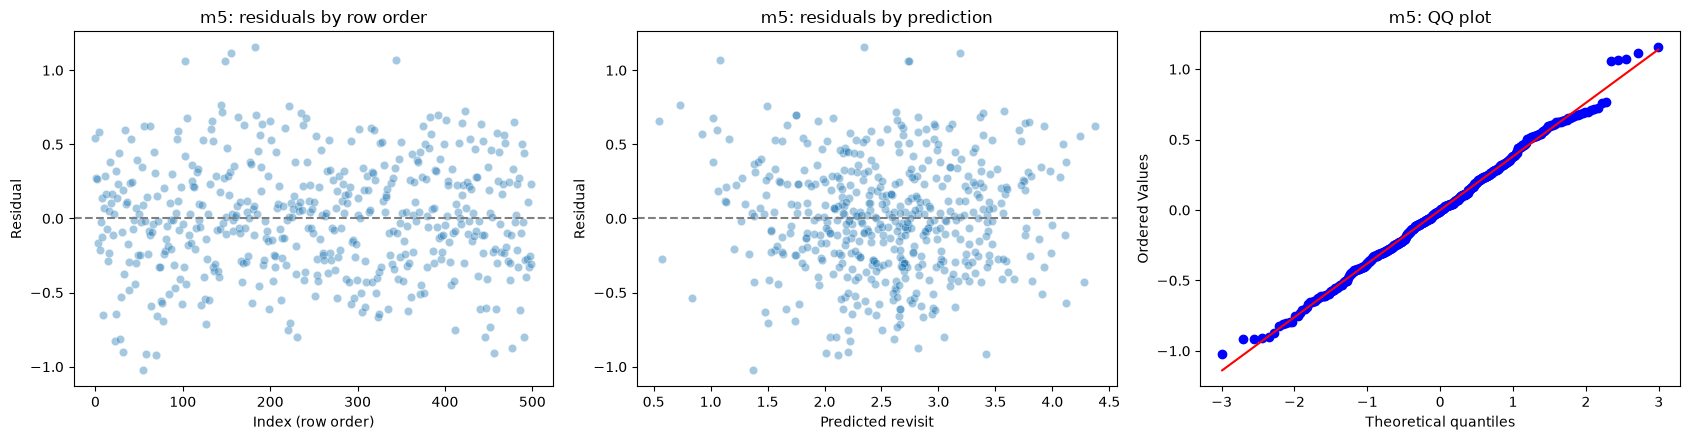

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.scatterplot(x=df.index, y=m5.resid, alpha=0.4, ax=axes[0])
axes[0].axhline(0, color='grey', linestyle='--')
axes[0].set_xlabel('Index (row order)'); axes[0].set_ylabel('Residual')
axes[0].set_title('m5: residuals by row order')

sns.scatterplot(x=m5.fittedvalues, y=m5.resid, alpha=0.4, ax=axes[1])
axes[1].axhline(0, color='grey', linestyle='--')
axes[1].set_xlabel('Predicted revisit'); axes[1].set_ylabel('Residual')
axes[1].set_title('m5: residuals by prediction')

import scipy.stats as stats
stats.probplot(m5.resid, plot=axes[2])
axes[2].set_title('m5: QQ plot')

plt.tight_layout()
plt.show()

---
# Part 5 · Show it — the coefficient plot

A table of slopes is hard to read. A picture of them, with their confidence intervals, is not.

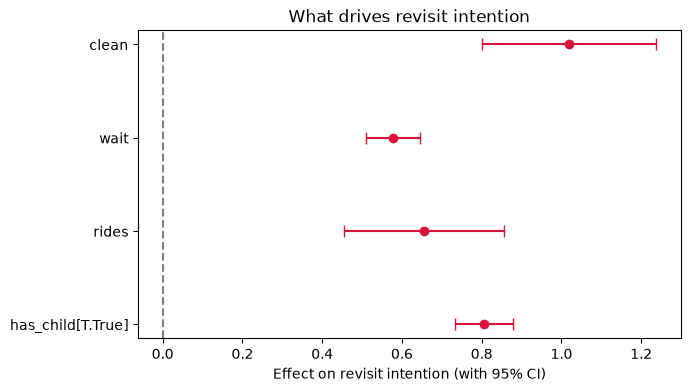

In [20]:
coefs = m5.conf_int()
coefs['estimate'] = m5.params
coefs = coefs.drop(index='Intercept')
coefs.columns = ['low', 'high', 'estimate']

plt.figure(figsize=(7, 4))
plt.errorbar(x=coefs['estimate'], y=coefs.index,
             xerr=[coefs['estimate'] - coefs['low'], coefs['high'] - coefs['estimate']],
             fmt='o', color='crimson', capsize=4)
plt.axvline(0, color='grey', linestyle='--')
plt.xlabel('Effect on revisit intention (with 95% CI)')
plt.title('What drives revisit intention')
plt.show()

📖 Read-level — copy it for your own model. Each dot is a slope; the bar is its 95% interval. An interval crossing zero is compatible with zero and with the other values in that interval. All four intervals here exclude zero. The category coefficient is a group difference; the satisfaction coefficients are per score point. Their sizes are not a direct ranking of business value.

This is the chart for your presentation. One picture, every finding.

## Worked interaction example: rides satisfaction and child status

**Question:** is the association between rides satisfaction and revisit the same for visitors with and without children? A model without this interaction uses the same rides slope for both groups. The interaction lets the two slopes differ.

This example uses **rides**. Question 8 asks you to investigate **waiting** satisfaction yourself.

Let **C = 0** for visitors without children and **C = 1** for visitors with children. The term `rides:has_child` means **rides × C**. It is zero for the first group and equals rides for the second group. `ols` builds it from the formula.

The fitted equation is:

Predicted revisit = −6.1215 − 0.7780C + 0.3964 × rides + 0.3681 × (rides × C) + 0.5745 × wait + 1.0051 × clean.

Hold wait and clean scores constant when comparing the rides slopes.

In [21]:
m_rides_interaction = ols(
    'revisit ~ has_child + rides + wait + clean + rides:has_child', data=df).fit()
print(m_rides_interaction.params)
print(m_rides_interaction.pvalues)
print("Rides slope without children:", m_rides_interaction.params['rides'])
print("Rides slope with children:", m_rides_interaction.params['rides'] +
      m_rides_interaction.params['rides:has_child[T.True]'])

Intercept                 -6.121464
has_child[T.True]         -0.778011
rides                      0.396408
rides:has_child[T.True]    0.368110
wait                       0.574502
clean                      1.005124
dtype: float64
Intercept                  3.549016e-26
has_child[T.True]          2.023129e-01
rides                      5.463530e-03
rides:has_child[T.True]    9.472278e-03
wait                       4.484125e-51
clean                      2.389618e-18
dtype: float64
Rides slope without children: 0.39640776719266013
Rides slope with children: 0.7645182465804938


### Substitute each group into the equation

| Group | C | Interaction term | Full rides slope |
|---|---|---|---|
| Without children | 0 | rides × 0 = 0 | 0.3964 |
| With children | 1 | rides × 1 = rides | 0.3964 + 0.3681 = 0.7645 |

**A concrete reading:** for a one point higher rides satisfaction score, predicted revisit is about 0.40 points higher for visitors without children and about 0.76 points higher for visitors with children, at the same wait and clean satisfaction scores. These are changes in the predicted score, not the predicted score itself.

The interaction coefficient, **0.3681**, is the **difference between slopes**. It is not the full rides slope for visitors with children.

**What does the p value test?** H₀ says the extra rides slope is zero, so the two groups have the same rides slope. The interaction p value is **0.0095**. At the 5% level, the fitted model gives evidence that the adjusted rides association differs between groups in this simulated sample.

**Do not confuse the two group terms.** The `has_child[T.True]` coefficient, −0.7780, is the group gap when rides = 0, outside the observed range. It is not a constant group gap across all rides scores in this interaction model. It is also not the child coefficient from m5, which has no interaction.

This does not establish that improving rides causes a larger change for visitors with children. It does not establish that the group with a steeper slope always has a higher predicted score.

---
# 🛠 Exercise · Build your own

**Complete all eight questions in class. These exercises carry no marks.**


**1 · One predictor.** Fit `revisit ~ clean`. Report the slope, its p-value, its interval and R².

In [22]:
m1 = ols('revisit ~ clean', data=df).fit()

print('Slope:', round(m1.params['clean'], 3))
print('p-value:', round(m1.pvalues['clean'], 3))
print('95% CI:')
print(m1.conf_int().loc['clean'].round(3))
print('R²:', round(m1.rsquared, 3))


Slope: 1.985
p-value: 0.0
95% CI:
0    1.775
1    2.195
Name: clean, dtype: float64
R²: 0.409


**2 · Predict.** Using that model, what revisit score does it predict for a visitor who rates
cleanliness 4.0? And 5.0?

In [23]:
pred = m1.predict(pd.DataFrame({'clean': [4.0, 5.0]}))
print('Predicted revisit scores:')
print(pred.round(3))


Predicted revisit scores:
0    1.779
1    3.764
dtype: float64


**3 · Add one.** Fit `revisit ~ clean + wait`. What happened to the `clean` slope, and to R²?

The clean slope falls from about 1.985 to 1.539 after adding wait, while R² rises from 0.409 to 0.540. This means wait shares some of the same pattern as cleanliness, but cleanliness still retains a strong adjusted association.

In [24]:
m3 = ols('revisit ~ clean + wait', data=df).fit()

print('m3 coefficients:')
print(m3.params.round(3))
print('\nR²:', round(m3.rsquared, 3))
print('\nClean slope change:', round(m1.params['clean'], 3), '→', round(m3.params['clean'], 3))


m3 coefficients:
Intercept   -6.212
clean        1.539
wait         0.575
dtype: float64

R²: 0.54

Clean slope change: 1.985 → 1.539


**4 · Compare.** Is the two-predictor model significantly better than the one-predictor model?
Use `anova_lm`.

Yes. Comparing `revisit ~ clean` with `revisit ~ clean + wait` gives F = 142.39 and p ≈ 4.87e-29, so the two-predictor model fits significantly better.

In [25]:
anova_table = anova_lm(m1, m3)
print(anova_table)


   df_resid         ssr  df_diff    ss_diff           F        Pr(>F)
0     498.0  185.943231      0.0        NaN         NaN           NaN
1     497.0  144.533319      1.0  41.409912  142.394336  4.872080e-29


**5 · A category.** Add `has_child` to the model from question 3. Report its slope and say what it
means in words.

The `has_child[T.True]` slope is about +0.796. Holding cleanliness and wait constant, visitors with children are estimated to score about 0.80 points higher on revisit than visitors without children.

In [26]:
m_child = ols('revisit ~ clean + wait + has_child', data=df).fit()

print(m_child.params.round(3))
print('\nR²:', round(m_child.rsquared, 3))


Intercept           -6.915
has_child[T.True]    0.796
clean                1.564
wait                 0.587
dtype: float64

R²: 0.752


**6 · No code — the sentence for the park.** Using m5 from Part 4, the park has budget for **one**
improvement. Which satisfaction area should it spend on, and what is the one caveat you must attach?

Spend on cleanliness. The caveat is that this is observational evidence rather than proof that raising cleanliness would cause higher revisit, so the best interpretation is that cleanliness has the strongest adjusted association in the sample.

**7 · Put it together.** The park manager wants to build a **new games area** to bring visitors
back. The reason: *"Games satisfaction clearly goes with coming back."* Check that claim before the
money is spent. Each step uses what the step before it found.

1. **Fit.** Fit `revisit ~ games`. Report the slope, its p-value, its interval and R². On this alone,
   does the manager look right?
2. **Inspect predictor overlap.** Print the correlations between `games`, `rides`, `wait` and `clean`. Which score does `games` move with most? Strong overlap can make individual estimates less precise; it does not automatically require removing a predictor.
3. **Compare.** Add `games` to m5 from Part 4 and fit it. What happened to the `games` slope and its
   p-value? Then use `anova_lm` to compare m5 with your new model. By the rule in §3.1, which model wins?
4. **Recommend.** In two or three sentences for the manager: should a games area be the priority for
   bringing visitors back? Use your numbers, and add the one caveat.

- **Step 1:** The games-only slope is +0.855 (p ≈ 8.65e-25, 95% CI 0.700 to 1.010), and R² = 0.191. On its own, the manager looks partly right, but the fit is weak and the claim is not decisive.
- **Step 2:** `games` is most strongly correlated with `clean` (r ≈ 0.517), then `rides` (r ≈ 0.455), while `wait` is lower (r ≈ 0.299). That overlap means games and cleanliness move together, so a single games effect becomes less precise once the others are included.
- **Step 3:** After adding `games` to m5, the games slope falls to about +0.085 (p ≈ 0.086), and the model comparison gives p ≈ 0.086. By the nested-model rule, the simpler m5 wins because the extra term does not improve fit enough to justify the complexity.
- **Step 4 — for the manager:** No — a games area should not be the priority for bringing visitors back after adjustment. In the fuller model, rides, wait and cleanliness keep clear positive associations, while games adds almost nothing once those are included. Caveat: this remains observational evidence, not proof that changing one area would cause higher revisit.

In [27]:
m_games = ols('revisit ~ games', data=df).fit()
print('m_games coefficients:')
print(m_games.params.round(3))
print('\np-values:', m_games.pvalues.round(3).to_dict())
print('\n95% CI:')
print(m_games.conf_int().loc['games'].round(3))
print('\nR²:', round(m_games.rsquared, 3))

corr = df[['games', 'rides', 'wait', 'clean']].corr()
print('\nCorrelations:')
print(corr.round(3))

m_games_plus = ols('revisit ~ has_child + rides + wait + clean + games', data=df).fit()
print('\nAdded-games model coefficients:')
print(m_games_plus.params.round(3))
print('\nGames p-value:', round(m_games_plus.pvalues['games'], 3))
print('\nComparison with m5:')
print(anova_lm(m5, m_games_plus))


m_games coefficients:
Intercept   -0.801
games        0.855
dtype: float64

p-values: {'Intercept': 0.01, 'games': 0.0}

95% CI:
0    0.70
1    1.01
Name: games, dtype: float64

R²: 0.191

Correlations:
       games  rides   wait  clean
games  1.000  0.455  0.299  0.517
rides  0.455  1.000  0.314  0.790
wait   0.299  0.314  1.000  0.368
clean  0.517  0.790  0.368  1.000

Added-games model coefficients:
Intercept           -7.323
has_child[T.True]    0.802
rides                0.640
wait                 0.570
clean                0.967
games                0.085
dtype: float64

Games p-value: 0.086

Comparison with m5:
   df_resid        ssr  df_diff   ss_diff         F  Pr(>F)
0     495.0  71.869484      0.0       NaN       NaN     NaN
1     494.0  71.442299      1.0  0.427186  2.953849  0.0863


**8 · Interactions.**

Does the association between waiting satisfaction and revisit depend on whether visitors have children? `ols('revisit ~ has_child + rides + wait + clean + wait:has_child')` adds an **interaction** term.

Fit it. Ask your AI what the `wait:has_child[T.True]` row means. Then, in one sentence, what association does it show for visitors with children? Include a caution about causal claims.

**Your interpretation:** For visitors with children, each additional point of waiting satisfaction is associated with about 0.51 more revisit points than for visitors without children, holding rides and cleanliness constant; this is an observational association, not proof that reducing wait would cause higher revisit.

In [28]:
m_inter = ols('revisit ~ has_child + rides + wait + clean + wait:has_child', data=df).fit()
print(m_inter.params.round(3))
print('\nwait:has_child[T.True] =', round(m_inter.params['wait:has_child[T.True]'], 3))
print('p-value:', round(m_inter.pvalues['wait:has_child[T.True]'], 3))


Intercept                -5.910
has_child[T.True]        -0.988
rides                     0.629
wait                      0.232
wait:has_child[T.True]    0.512
clean                     1.003
dtype: float64

wait:has_child[T.True] = 0.512
p-value: 0.0


---
# ✅ Done — hand it in

**No cell is designed to fail.** `pairplot` and `summary()` are slow-ish; that is normal.

1. **Run All**, no red. 2. Save, **commit and sync**. 3. On Moodle: **this notebook**. 4. **Stop your Codespace**.

## What you can now do

- [ ] check straight-line relationships and collinearity **before** modelling
- [ ] say what the DV and IVs are, and which kinds of column each can be
- [ ] explain least squares (RSS) and where R² comes from (TSS and RSS)
- [ ] fit `ols('y ~ x')` and read the slope, its p-value, its interval, R², adjusted R² and the F-statistic
- [ ] explain what "holding the others constant" means for a slope in a multiple regression
- [ ] compare two nested models with `anova_lm` and keep the simpler unless the complex is significantly better
- [ ] put a yes/no column into a regression and read `[T.True]`
- [ ] name the five assumptions, and check residuals against the index, against the predictions, and with a QQ plot
- [ ] draw a coefficient plot and put it in a presentation
- [ ] test a claim with the steps together — fit, check an assumption, compare two models, recommend

## The rest of the semester

**No more new methods.** Weeks 12 and 13 are presentations. Your slides are due **before week 12**
whichever week you present.